# Chapter 1: The Noisy Bit

Companion notebook for **Chapter 1** of *Bernoulli Types: An Algebra of Approximate Computation*.
Source files: `book/chapters/ch01/`.

Chapter 1 introduces the single noisy bit: a Boolean value observed through a channel that
flips it with some probability. Two channels frame the whole book:

1. The **Binary Symmetric Channel (BSC)**: one crossover rate `epsilon` for both directions.
2. The **biased-coin asymmetric channel**: a false-positive rate `fpr` and a separate
   false-negative rate `fnr`.

This notebook:

1. Builds a BSC simulator and reads off empirical FPR and FNR from the four-cell confusion count.
2. Plots how the empirical rate estimates converge to the true rate as the sample size grows.
3. Builds the asymmetric simulator and recovers `fpr` and `fnr` separately.
4. Runs a Wald 95% confidence-interval coverage check, and watches coverage drift below 0.95
   at small sample sizes.
5. Closes with the open question the rest of the book keeps circling back to: what if the
   rates are not fixed, or the noise events are not independent?

**Conventions (matching book notation):**
- `epsilon` (`fpr`) = false-positive rate: probability of reporting `True` when the truth is `False`.
- `omega` (`fnr`) = false-negative rate: probability of reporting `False` when the truth is `True`.
- Boolean values are represented as `True` / `False` (or `1` / `0` in numpy arrays).
- A single shared `rng` (seeded) drives every simulation, so the notebook is reproducible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)

print(f"NumPy {np.__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")

NumPy 2.4.4
Matplotlib 3.10.9


## 1. The Binary Symmetric Channel

The BSC takes a Boolean input and flips it, independently for each bit, with crossover
probability `epsilon`. The same rate governs both directions: a `True` becomes `False`
with probability `epsilon`, and a `False` becomes `True` with probability `epsilon`.

`simulate_bsc` draws a random Boolean input array, then produces the channel output by
flipping each bit with probability `epsilon`. It returns both arrays so we can line up
input against output and count the four confusion cells.

In [2]:
def simulate_bsc(epsilon: float, n: int,
                 rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
    """Simulate n independent uses of a Binary Symmetric Channel.

    A random Boolean input array is drawn, then each bit is flipped
    independently with probability epsilon to form the output.

    Parameters
    ----------
    epsilon : float
        Crossover probability in [0, 1]. Same rate in both directions.
    n : int
        Number of bits to send through the channel.
    rng : np.random.Generator
        Random number generator.

    Returns
    -------
    inputs : ndarray of bool, shape (n,)
        The true input bits.
    outputs : ndarray of bool, shape (n,)
        The channel outputs (inputs with each bit flipped w.p. epsilon).
    """
    inputs = rng.uniform(size=n) < 0.5
    flip = rng.uniform(size=n) < epsilon
    outputs = np.where(flip, ~inputs, inputs)
    return inputs, outputs


def confusion_counts(inputs: np.ndarray,
                     outputs: np.ndarray) -> tuple[int, int, int, int]:
    """Count the four confusion cells from aligned input/output arrays.

    Returns (tp, fp, tn, fn):
      tp : true positive  -- input True,  output True
      fp : false positive -- input False, output True
      tn : true negative  -- input False, output False
      fn : false negative -- input True,  output False
    """
    tp = int(np.sum(inputs & outputs))
    fp = int(np.sum(~inputs & outputs))
    tn = int(np.sum(~inputs & ~outputs))
    fn = int(np.sum(inputs & ~outputs))
    return tp, fp, tn, fn


# Quick smoke test: a perfect channel (epsilon = 0) never flips.
inp, out = simulate_bsc(epsilon=0.0, n=10_000, rng=rng)
assert np.array_equal(inp, out), "epsilon=0 channel should be the identity"
print("simulate_bsc(epsilon=0.0) is the identity channel: confirmed.")

simulate_bsc(epsilon=0.0) is the identity channel: confirmed.


## 2. Empirical FPR and FNR from the Four Cells

Send `n = 1000` bits through a BSC with `epsilon = 0.1`. The empirical false-positive rate
is the fraction of `False` inputs that came out `True`:

$$\hat{\epsilon} = \frac{\mathrm{FP}}{\mathrm{FP} + \mathrm{TN}}$$

and the empirical false-negative rate is the fraction of `True` inputs that came out `False`:

$$\hat{\omega} = \frac{\mathrm{FN}}{\mathrm{FN} + \mathrm{TP}}$$

For a BSC, both should land near the true `epsilon = 0.1`, up to sampling noise.

In [3]:
TRUE_EPSILON = 0.1
n_demo = 1000

inputs, outputs = simulate_bsc(epsilon=TRUE_EPSILON, n=n_demo, rng=rng)
tp, fp, tn, fn = confusion_counts(inputs, outputs)

fpr_hat = fp / (fp + tn)
fnr_hat = fn / (fn + tp)

print(f"BSC with true epsilon = {TRUE_EPSILON}, n = {n_demo}")
print()
print("Confusion cells:")
print(f"  TP (in True,  out True ) = {tp:5d}")
print(f"  FP (in False, out True ) = {fp:5d}")
print(f"  TN (in False, out False) = {tn:5d}")
print(f"  FN (in True,  out False) = {fn:5d}")
print(f"  total                    = {tp + fp + tn + fn:5d}")
print()
print(f"  empirical FPR_hat = FP / (FP + TN) = {fp:3d} / {fp + tn:3d} = {fpr_hat:.4f}")
print(f"  empirical FNR_hat = FN / (FN + TP) = {fn:3d} / {fn + tp:3d} = {fnr_hat:.4f}")
print(f"  true rate (both)                   = {TRUE_EPSILON:.4f}")
print()
print(f"  FPR_hat absolute error: {abs(fpr_hat - TRUE_EPSILON):.4f}")
print(f"  FNR_hat absolute error: {abs(fnr_hat - TRUE_EPSILON):.4f}")
print()
print("At n = 1000 the estimates are close to 0.1 but visibly noisy. Section 3")
print("watches that noise shrink as n grows.")

BSC with true epsilon = 0.1, n = 1000

Confusion cells:
  TP (in True,  out True ) =   439
  FP (in False, out True ) =    58
  TN (in False, out False) =   467
  FN (in True,  out False) =    36
  total                    =  1000

  empirical FPR_hat = FP / (FP + TN) =  58 / 525 = 0.1105
  empirical FNR_hat = FN / (FN + TP) =  36 / 475 = 0.0758
  true rate (both)                   = 0.1000

  FPR_hat absolute error: 0.0105
  FNR_hat absolute error: 0.0242

At n = 1000 the estimates are close to 0.1 but visibly noisy. Section 3
watches that noise shrink as n grows.


## 3. Convergence: Empirical Rates vs Sample Size

The empirical rate is a sample average, so by the law of large numbers it converges to
the true rate as `n` grows. The spread of $\hat{\epsilon}$ around `epsilon` shrinks like
$1/\sqrt{n}$.

We sweep `n` over `{10, 100, 1000, 10000, 100000}`, run a fresh BSC simulation at each
size, and plot the empirical FPR and FNR against the true `epsilon = 0.1` reference line.

       n     FPR_hat     FNR_hat   |FPR_hat - 0.1|
--------------------------------------------------
      10      0.2000      0.0000            0.1000
     100      0.1569      0.1020            0.0569
    1000      0.1141      0.1022            0.0141
   10000      0.1029      0.1011            0.0029
  100000      0.0977      0.1009            0.0023


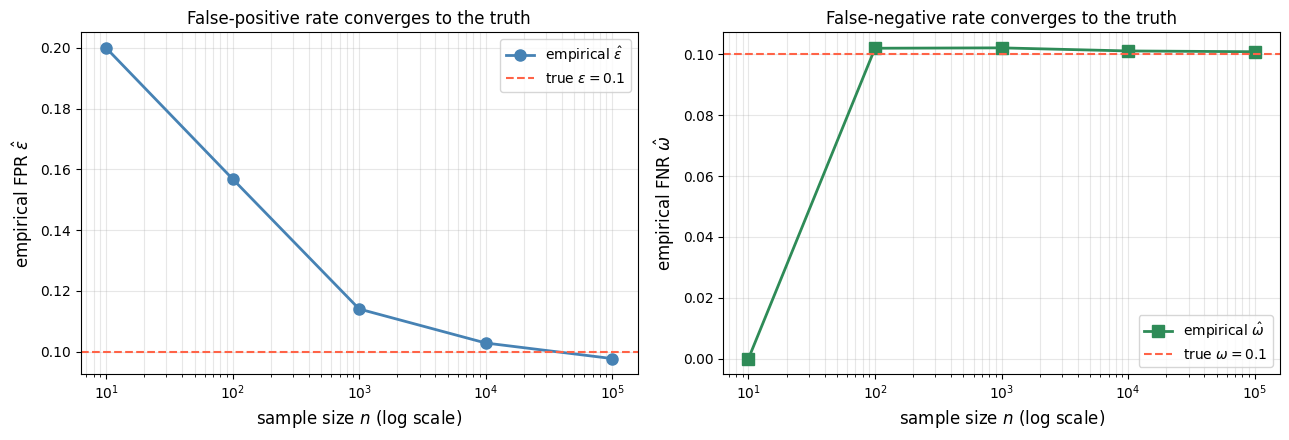


At n = 100,000, FPR_hat = 0.0977 and FNR_hat = 0.1009,
both within 0.01 of the true 0.1. At n = 10 the estimate can be far off:
a single bit changes the rate by 0.1 or 0.2.


In [4]:
n_grid = [10, 100, 1000, 10_000, 100_000]
fpr_hats = []
fnr_hats = []

for n in n_grid:
    inp, out = simulate_bsc(epsilon=TRUE_EPSILON, n=n, rng=rng)
    tp, fp, tn, fn = confusion_counts(inp, out)
    fpr_hats.append(fp / (fp + tn))
    fnr_hats.append(fn / (fn + tp))

print(f"{'n':>8s}  {'FPR_hat':>10s}  {'FNR_hat':>10s}  {'|FPR_hat - 0.1|':>16s}")
print("-" * 50)
for n, fph, fnh in zip(n_grid, fpr_hats, fnr_hats):
    print(f"{n:>8d}  {fph:>10.4f}  {fnh:>10.4f}  {abs(fph - TRUE_EPSILON):>16.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].semilogx(n_grid, fpr_hats, "o-", color="steelblue", linewidth=2,
                 markersize=8, label=r"empirical $\hat{\epsilon}$")
axes[0].axhline(TRUE_EPSILON, color="tomato", linestyle="--", linewidth=1.5,
                label=rf"true $\epsilon = {TRUE_EPSILON}$")
axes[0].set_xlabel("sample size $n$ (log scale)", fontsize=12)
axes[0].set_ylabel(r"empirical FPR $\hat{\epsilon}$", fontsize=12)
axes[0].set_title("False-positive rate converges to the truth", fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(True, which="both", alpha=0.3)

axes[1].semilogx(n_grid, fnr_hats, "s-", color="seagreen", linewidth=2,
                 markersize=8, label=r"empirical $\hat{\omega}$")
axes[1].axhline(TRUE_EPSILON, color="tomato", linestyle="--", linewidth=1.5,
                label=rf"true $\omega = {TRUE_EPSILON}$")
axes[1].set_xlabel("sample size $n$ (log scale)", fontsize=12)
axes[1].set_ylabel(r"empirical FNR $\hat{\omega}$", fontsize=12)
axes[1].set_title("False-negative rate converges to the truth", fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

print()
print(f"At n = {n_grid[-1]:,}, FPR_hat = {fpr_hats[-1]:.4f} and FNR_hat = {fnr_hats[-1]:.4f},")
print(f"both within 0.01 of the true {TRUE_EPSILON}. At n = 10 the estimate can be far off:")
print("a single bit changes the rate by 0.1 or 0.2.")

## 4. The Biased-Coin Asymmetric Channel

The BSC has one knob. Most real approximate data structures have two: a Bloom filter,
for instance, has false positives but no false negatives. The general channel uses two
independent rates:

- `fpr`: a `False` input is reported `True` with this probability.
- `fnr`: a `True` input is reported `False` with this probability.

Think of it as two biased coins: one coin decides whether to corrupt a negative input,
a different coin decides whether to corrupt a positive input. `simulate_asymmetric`
splits the input array by truth value and applies the matching rate to each part.

In [5]:
def simulate_asymmetric(fpr: float, fnr: float, n: int,
                        rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
    """Simulate n independent uses of an asymmetric binary channel.

    A random Boolean input array is drawn. Each True input is flipped with
    probability fnr; each False input is flipped with probability fpr.

    Parameters
    ----------
    fpr : float
        False-positive rate in [0, 1]: Pr(output True | input False).
    fnr : float
        False-negative rate in [0, 1]: Pr(output False | input True).
    n : int
        Number of bits to send through the channel.
    rng : np.random.Generator
        Random number generator.

    Returns
    -------
    inputs : ndarray of bool, shape (n,)
        The true input bits.
    outputs : ndarray of bool, shape (n,)
        The channel outputs.
    """
    inputs = rng.uniform(size=n) < 0.5
    # Per-bit flip probability depends on the true value of that bit.
    flip_prob = np.where(inputs, fnr, fpr)
    flip = rng.uniform(size=n) < flip_prob
    outputs = np.where(flip, ~inputs, inputs)
    return inputs, outputs


# Smoke test: fnr = 0 means no positive is ever corrupted (a Z-channel / Bloom-like case).
inp, out = simulate_asymmetric(fpr=0.3, fnr=0.0, n=10_000, rng=rng)
assert np.all(out[inp]), "fnr=0 channel must never flip a True input"
print("simulate_asymmetric(fnr=0.0) never corrupts a positive input: confirmed.")

simulate_asymmetric(fnr=0.0) never corrupts a positive input: confirmed.


## 5. Recovering Two Rates Separately

With `fpr = 0.05` and `fnr = 0.2` the two rates are quite different. The point of the
four-cell confusion count is that it keeps the two directions apart: FPR is estimated
only from the negative inputs, FNR only from the positive inputs. We send a large sample
through the channel and check that each estimate lands near its own true rate.

In [6]:
TRUE_FPR = 0.05
TRUE_FNR = 0.2
n_asym = 200_000

inputs, outputs = simulate_asymmetric(fpr=TRUE_FPR, fnr=TRUE_FNR, n=n_asym, rng=rng)
tp, fp, tn, fn = confusion_counts(inputs, outputs)

fpr_recovered = fp / (fp + tn)
fnr_recovered = fn / (fn + tp)

print(f"Asymmetric channel: true fpr = {TRUE_FPR}, true fnr = {TRUE_FNR}, n = {n_asym:,}")
print()
print("Confusion cells:")
print(f"  TP = {tp:6d}    FN = {fn:6d}   (positive inputs: {tp + fn:6d})")
print(f"  FP = {fp:6d}    TN = {tn:6d}   (negative inputs: {fp + tn:6d})")
print()
print(f"  recovered FPR = FP / (FP + TN) = {fpr_recovered:.4f}   (true {TRUE_FPR})")
print(f"  recovered FNR = FN / (FN + TP) = {fnr_recovered:.4f}   (true {TRUE_FNR})")
print()
print(f"  FPR absolute error: {abs(fpr_recovered - TRUE_FPR):.4f}")
print(f"  FNR absolute error: {abs(fnr_recovered - TRUE_FNR):.4f}")
print()
assert abs(fpr_recovered - TRUE_FPR) < 0.01, "recovered FPR drifted too far"
assert abs(fnr_recovered - TRUE_FNR) < 0.02, "recovered FNR drifted too far"
print("Both rates recovered within tolerance. The asymmetry is preserved:")
print("the channel is not a BSC, and the confusion count sees that.")

Asymmetric channel: true fpr = 0.05, true fnr = 0.2, n = 200,000

Confusion cells:
  TP =  80403    FN =  20067   (positive inputs: 100470)
  FP =   4922    TN =  94608   (negative inputs:  99530)

  recovered FPR = FP / (FP + TN) = 0.0495   (true 0.05)
  recovered FNR = FN / (FN + TP) = 0.1997   (true 0.2)

  FPR absolute error: 0.0005
  FNR absolute error: 0.0003

Both rates recovered within tolerance. The asymmetry is preserved:
the channel is not a BSC, and the confusion count sees that.


## 6. Confidence Interval Coverage

A point estimate $\hat{\epsilon}$ is not the whole story. We also want an interval that
captures the true rate with a stated probability. The textbook **Wald 95% interval** for
a rate estimated from `n_0` negative inputs is

$$\hat{\epsilon} \pm 1.96 \sqrt{\frac{\hat{\epsilon}(1 - \hat{\epsilon})}{n_0}}.$$

*Coverage* is the property we actually care about: if the interval is honest, then across
many repetitions of the experiment it should contain the true rate about 95% of the time.

We test this directly. Fix `n_0 = n_1 = 240`, run the asymmetric-channel experiment
`M = 1000` times, build the Wald interval for `fpr` each time, and count how often the
true `fpr = 0.05` falls inside. Even at this sample size, expect mild under-coverage:
the Wald interval is biased downward when the true rate is near 0.

In [7]:
Z_95 = 1.959963984540054  # standard normal 97.5th percentile


def wald_interval(successes: int, trials: int, z: float = Z_95) -> tuple[float, float]:
    """Wald (normal-approximation) confidence interval for a binomial rate.

    Parameters
    ----------
    successes : int
        Number of observed successes (here: false positives).
    trials : int
        Number of trials (here: negative inputs n_0).
    z : float
        Standard-normal critical value (1.96 for a 95% interval).

    Returns
    -------
    (lo, hi) : tuple of float
        Lower and upper interval endpoints, clipped to [0, 1].
    """
    p_hat = successes / trials
    half_width = z * np.sqrt(p_hat * (1.0 - p_hat) / trials)
    return max(0.0, p_hat - half_width), min(1.0, p_hat + half_width)


def coverage_experiment(true_fpr: float, true_fnr: float, n0: int, n1: int,
                        n_reps: int, rng: np.random.Generator) -> float:
    """Estimate Wald 95% CI coverage for the FPR estimate.

    Repeats the channel experiment n_reps times. Each repetition draws
    n0 negative inputs and n1 positive inputs, builds the Wald interval
    for the FPR from the negative inputs, and checks whether true_fpr
    falls inside. Returns the fraction of intervals that covered.
    """
    covered = 0
    for _ in range(n_reps):
        # n0 negative inputs: each flips to a false positive with prob true_fpr.
        fp = int(np.sum(rng.uniform(size=n0) < true_fpr))
        # n1 positive inputs are drawn for completeness (the FNR side); the
        # FPR interval only uses the negative-input count.
        _ = int(np.sum(rng.uniform(size=n1) < true_fnr))
        lo, hi = wald_interval(fp, n0)
        if lo <= true_fpr <= hi:
            covered += 1
    return covered / n_reps


M = 1000
n0 = n1 = 240
coverage_240 = coverage_experiment(TRUE_FPR, TRUE_FNR, n0, n1, M, rng)

print(f"Wald 95% CI coverage check for fpr = {TRUE_FPR}")
print(f"  n_0 = n_1 = {n0}, repetitions M = {M}")
print()
print(f"  empirical coverage = {coverage_240:.3f}")
print(f"  nominal coverage   = 0.950")
print()
if coverage_240 < 0.95:
    print(f"  The interval under-covers by {0.95 - coverage_240:.3f}. This is expected:")
    print("  the Wald interval is known to under-cover when the true rate is near 0.")
else:
    print("  Coverage is at or above nominal for this run.")

Wald 95% CI coverage check for fpr = 0.05
  n_0 = n_1 = 240, repetitions M = 1000

  empirical coverage = 0.949
  nominal coverage   = 0.950

  The interval under-covers by 0.001. This is expected:
  the Wald interval is known to under-cover when the true rate is near 0.


## 7. Coverage vs Sample Size

Under-coverage is worst when the sample is small. We sweep `n_0` over
`{20, 50, 100, 500, 2000}`, rerun the coverage experiment at each size, and plot empirical
coverage against the nominal 0.95 line. The gap should close as `n_0` grows.

     n_0    empirical coverage     gap from 0.95
------------------------------------------------
      20                 0.666             0.284
      50                 0.922             0.028
     100                 0.880             0.070
     500                 0.928             0.022
    2000                 0.954            -0.004


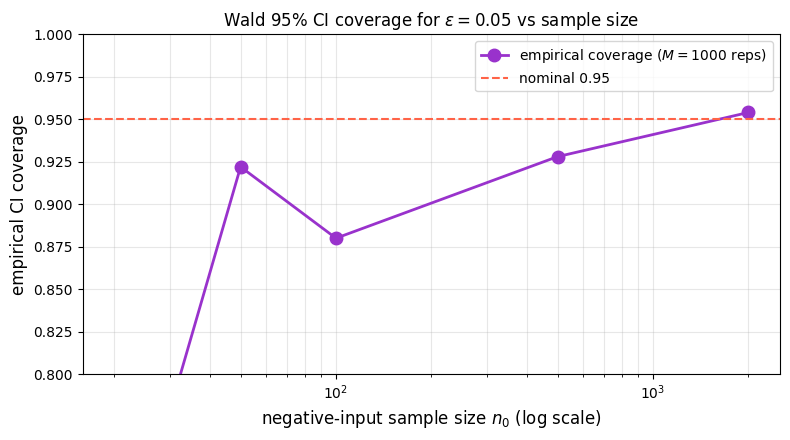


At n_0 = 20 the coverage is 0.666; by n_0 = 2000
it is 0.954, close to the nominal 0.95. The interval is
asymptotically honest, but small samples need a better construction.


In [8]:
n0_grid = [20, 50, 100, 500, 2000]
coverages = []

for n0 in n0_grid:
    cov = coverage_experiment(TRUE_FPR, TRUE_FNR, n0, n0, M, rng)
    coverages.append(cov)

print(f"{'n_0':>8s}  {'empirical coverage':>20s}  {'gap from 0.95':>16s}")
print("-" * 48)
for n0, cov in zip(n0_grid, coverages):
    print(f"{n0:>8d}  {cov:>20.3f}  {0.95 - cov:>16.3f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(n0_grid, coverages, "o-", color="darkorchid", linewidth=2, markersize=9,
            label=f"empirical coverage ($M = {M}$ reps)")
ax.axhline(0.95, color="tomato", linestyle="--", linewidth=1.5,
           label="nominal 0.95")
ax.set_xlabel("negative-input sample size $n_0$ (log scale)", fontsize=12)
ax.set_ylabel("empirical CI coverage", fontsize=12)
ax.set_title(rf"Wald 95% CI coverage for $\epsilon = {TRUE_FPR}$ vs sample size",
             fontsize=12)
ax.legend(fontsize=10)
ax.set_ylim(0.80, 1.0)
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print()
print(f"At n_0 = {n0_grid[0]} the coverage is {coverages[0]:.3f}; by n_0 = {n0_grid[-1]}")
print(f"it is {coverages[-1]:.3f}, close to the nominal 0.95. The interval is")
print("asymptotically honest, but small samples need a better construction.")

## 8. Why the Wald Interval Drifts

The plot above shows the Wald interval under-covering at small `n_0`. This is a
well-documented weakness, not a bug in the simulation. The Wald interval is built on a
normal approximation to the binomial, and that approximation is poor exactly where we
are working here: a small sample with a true rate near 0 (or, symmetrically, near 1).

Two failure modes compound:

- When the true rate is near 0, a sample can easily produce zero false positives. Then
  $\hat{\epsilon} = 0$, the estimated standard error $\sqrt{\hat{\epsilon}(1 - \hat{\epsilon})/n_0}$
  collapses to 0, and the interval is the single point $\{0\}$. It cannot cover any
  positive true rate.
- The normal approximation is symmetric, but a rate near a boundary has a skewed
  sampling distribution. A symmetric interval is the wrong shape.

**Chapter 7** (Part II, Classification Measures) treats interval estimation properly.
The standard better-behaved alternatives are the **Wilson score interval** and the
**Clopper-Pearson exact interval**; both keep their coverage near 0.95 even for small
samples with extreme rates. We do not implement them here. The point of this notebook
is the failure, observed honestly, so that the fix in chapter 7 has something to fix.

## 9. The Open Question

Everything in this notebook rests on two assumptions that we never questioned:

1. **The rates are fixed.** Every bit through `simulate_bsc` used the same `epsilon`;
   every negative input in the coverage experiment flipped with the same `fpr`. We treated
   `epsilon` as one number to estimate.
2. **The noise events are independent.** Each call to `rng.uniform` was its own draw.
   No bit's corruption told us anything about any other bit's corruption.

Both assumptions can fail, and when they do, the noisy-bit picture stops being enough:

- *What if the rates vary across samples?* Suppose `epsilon` is itself drawn from some
  distribution, different for each query, or drifts over time. Then there is no single
  true rate for $\hat{\epsilon}$ to converge to. The convergence plot in Section 3 would
  still produce a number, but that number would be an average over a moving target, and
  the confidence interval would be answering the wrong question.
- *What if the noise events are correlated across queries?* Suppose a shared cause, a bad
  hash seed, a burst of interference, corrupts many bits together. Then the four-cell
  counts are no longer sums of independent indicators. The $1/\sqrt{n}$ shrinkage in
  Section 3 would be too optimistic, and the Wald interval, already shaky, would be
  badly miscalibrated for a reason that has nothing to do with the boundary effect in
  Section 8.

These are not edge cases to patch. They are the boundary of the model. The Bernoulli
framework that the rest of the book builds, sets, maps, relations, the whole algebra,
assumes fixed rates and independent error events throughout. Knowing where that
assumption holds, and where it does not, is the difference between using the framework
and misusing it.

**Chapter 16** is the negative-space chapter: it works through what the Bernoulli model
is *not*, and varying rates and correlated noise are two of its central examples. When
you reach chapter 16, this notebook is the concrete picture it is pushing against.

---

## Closing: Cross-References and Next Steps

**Chapter 1** establishes the single noisy bit: the BSC, the biased-coin asymmetric
channel, empirical rate estimation, and the honest limits of a small-sample confidence
interval.

**Chapter 2** (Binary Channels and Model Order) lifts the noisy bit into the
$2 \times 2$ channel matrix, derives the BSC composition formula, and introduces model
order. Its notebook: `python/notebooks/ch02-binary-channels.ipynb`.

**Chapter 7** (Classification Measures) returns to interval estimation and gives the
Wilson and Clopper-Pearson intervals that fix the under-coverage seen in Section 7.

**Chapter 16** (when the framework is not Bernoulli) returns to Section 9's open
question: varying rates and correlated noise as the negative space of the model.

**Summary of what this notebook showed:**

| Section | Claim | Shown |
|---------|-------|-------|
| 1-2 | BSC simulation; empirical FPR/FNR from the four confusion cells | Yes (n = 1000) |
| 3 | Empirical rates converge to the true rate as $n$ grows | Yes ($n$ up to 100k) |
| 4-5 | Asymmetric channel; `fpr` and `fnr` recovered separately | Yes (n = 200k) |
| 6 | Wald 95% CI coverage near nominal at $n_0 = 240$ | Yes ($M = 1000$ reps) |
| 7 | Coverage drifts below 0.95 at small $n_0$, recovers as $n_0$ grows | Yes |
| 8 | The drift is the Wald interval's known boundary weakness | Explained |
| 9 | Fixed rates and independent noise are assumptions, not facts | Open question -> ch 16 |